# Reuseable function for fetching data

This function would let us retreive different type of data, based on what the Task is asking for. Reusiong this function will save us time and space when answering this deliverable.

The code for retrieving and structuring the data is adapted from MET's Python example for Frost [1].

In [1]:
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

client_id = Path("frost_client_id.txt").read_text().strip()

In [2]:
def get_frost_data(element, referencetime, source='SN17850') -> pd.DataFrame:
    """Fetch daily observations from Frost and return them as a DataFrame."""
    # Define endpoint and parameters
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': source,
        'elements': element,
        'referencetime': referencetime,
    }
    # Issue an HTTP GET request and extract JSON data
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    response_json = r.json()

    # Stop with a clear message if the request did not work
    if r.status_code != 200:
        raise RuntimeError('Error %s: %s (%s)' % (
            r.status_code,
            response_json['error']['message'],
            response_json['error']['reason'],
        ))
    data = response_json['data']

    # Build a DataFrame with one row per observation
    rows = []
    for i in range(len(data)):
        row = pd.DataFrame(data[i]['observations'])
        row['referenceTime'] = data[i]['referenceTime']
        rows.append(row)
    df = pd.concat(rows, ignore_index=True)

    # Convert time and keep one measurement per day
    df['referenceTime'] = pd.to_datetime(df['referenceTime'], utc=True).dt.tz_convert(None)
    df = df[df['timeOffset'] == df['timeOffset'].iloc[0]]
    return df[['referenceTime', 'value']].reset_index(drop=True)

# Task 1

The data comes back as a list with one entry pr day. Each entry contains a list of observations. The next cells will turn this into a pd.Dataframe. The MET version is using an older code, so pd.concat() will be used insteand of df.append()

In [3]:
df = get_frost_data('mean(air_temperature P1D)', '2025-01-01/2026-01-01')

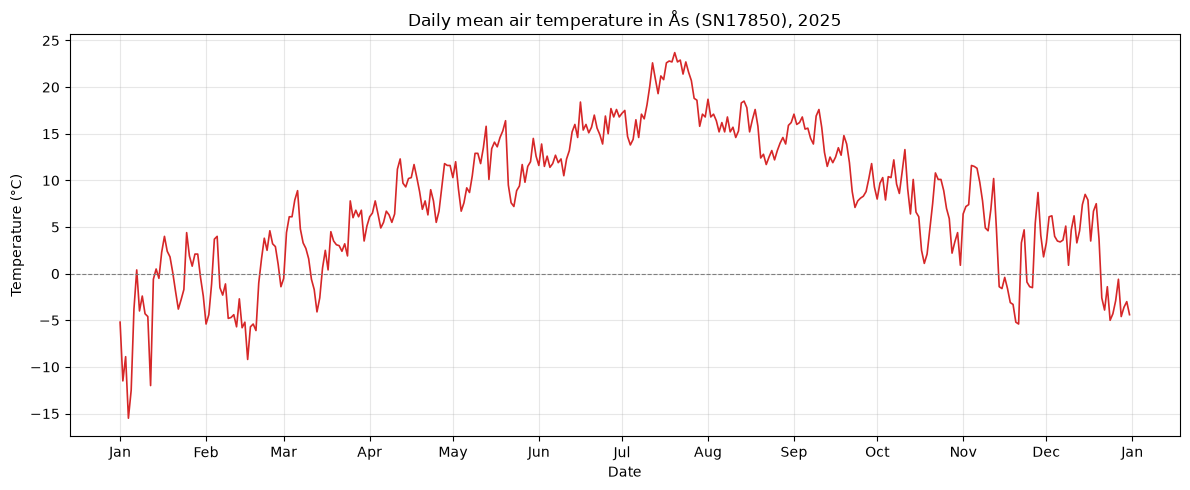

In [4]:
# Plot the daily mean temperature
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['referenceTime'], df['value'], color='tab:red', linewidth=1.2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås (SN17850), 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [5]:
# Summary table with mean, median, min and max temperature
summary = pd.DataFrame({
    'Temperature 2025 (°C)': [
        df['value'].mean(),
        df['value'].median(),
        df['value'].min(),
        df['value'].max(),
    ]
}, index=['Mean', 'Median', 'Min', 'Max']).round(1)

print(summary)

        Temperature 2025 (°C)
Mean                      7.9
Median                    8.3
Min                     -15.5
Max                      23.7


# Task 2

The next block retrieves the daily precipitation for 2025 from the same station.

In [6]:
precip = get_frost_data('sum(precipitation_amount P1D)', '2025-01-01/2026-01-01')

In [7]:
# Combine temperature and precipitation on the date
temp_day = df.assign(date=df['referenceTime'].dt.date)[['date', 'value']]
precip_day = precip.assign(date=precip['referenceTime'].dt.date)[['date', 'value']]
weather = pd.merge(temp_day, precip_day, on='date', suffixes=('_temp', '_precip'))
weather['date'] = pd.to_datetime(weather['date'])
print('Days with both temperature and precipitation: %s' % len(weather))

Days with both temperature and precipitation: 365


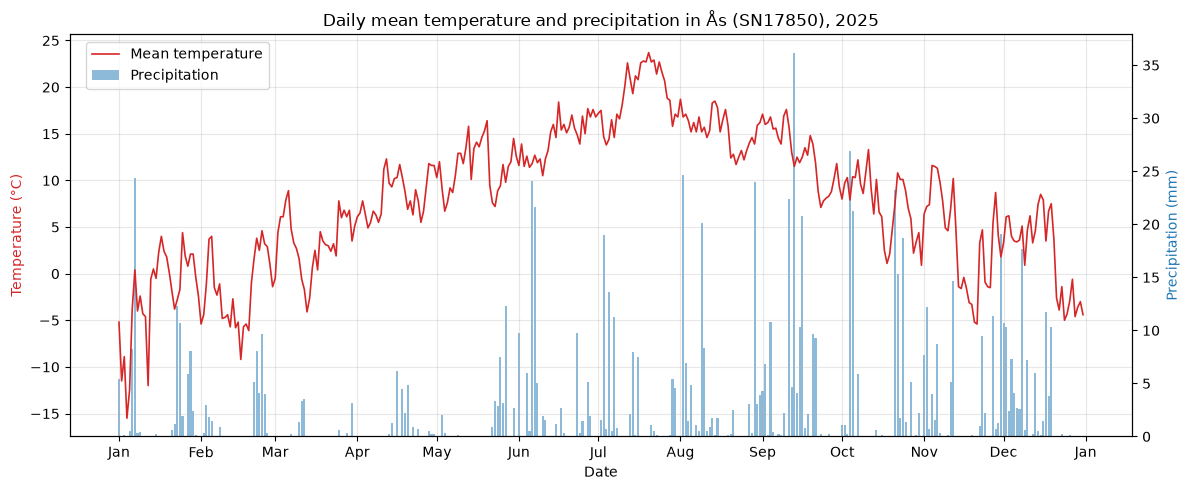

In [8]:
# Plot temperature (line, left axis) and precipitation (bars, right axis)
fig, ax1 = plt.subplots(figsize=(12, 5))

ax2 = ax1.twinx()
ax2.bar(weather['date'], weather['value_precip'], color='tab:blue', alpha=0.5, label='Precipitation')
ax2.set_ylabel('Precipitation (mm)', color='tab:blue')

ax1.plot(weather['date'], weather['value_temp'], color='tab:red', linewidth=1.2, label='Mean temperature')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.set_xlabel('Date')
ax1.set_zorder(ax2.get_zorder() + 1)   # draw the temperature line on top of the bars
ax1.patch.set_visible(False)

ax1.set_title('Daily mean temperature and precipitation in Ås (SN17850), 2025')
ax1.grid(alpha=0.3)
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.92))

ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

fig.tight_layout()
plt.show()

In [9]:
# Summary of precipitation in 2025
summary_precip = pd.DataFrame({
    'Precipitation 2025': [
        precip['value'].sum(),
        (precip['value'] >= 1).sum(),
        precip['value'].max(),
        precip.loc[precip['value'].idxmax(), 'referenceTime'].date(),
    ]
}, index=['Total (mm)', 'Days with ≥ 1 mm', 'Max per day (mm)', 'Wettest day'])

print(summary_precip)

                 Precipitation 2025
Total (mm)                    942.2
Days with ≥ 1 mm                123
Max per day (mm)               36.1
Wettest day              2025-09-13


# Task 3

In [10]:
df_1925 = get_frost_data('mean(air_temperature P1D)', '1925-01-01/1926-01-01')
print('Number of days in 1925: %s' % len(df_1925))

Number of days in 1925: 365


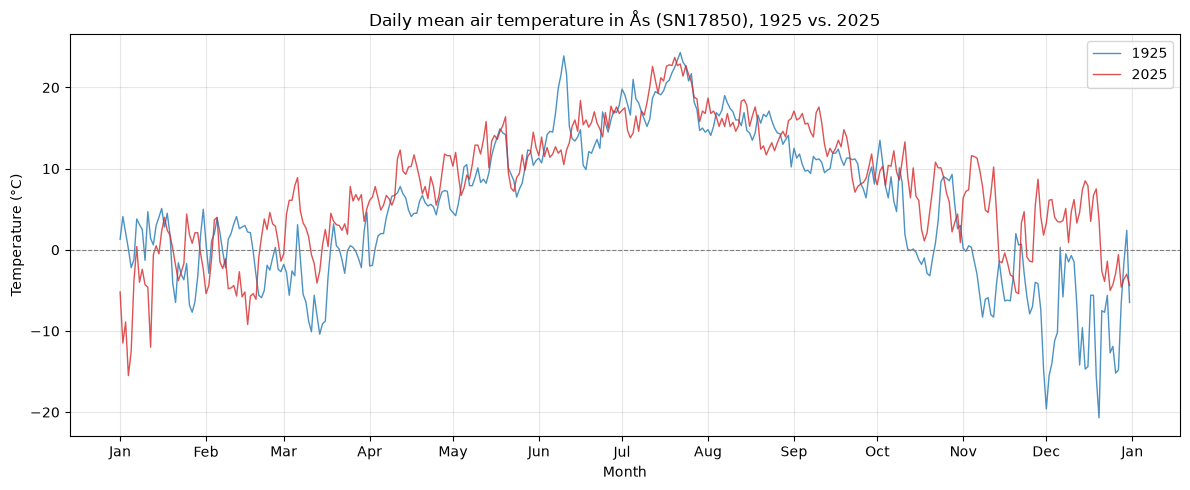

In [11]:
# Shift 1925 forward 100 years so both years share the same x-axis
df_1925['plotTime'] = df_1925['referenceTime'] + pd.DateOffset(years=100)

# Plot both years in the same figure
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_1925['plotTime'], df_1925['value'], color='tab:blue', linewidth=1, alpha=0.8, label='1925')
ax.plot(df['referenceTime'], df['value'], color='tab:red', linewidth=1, alpha=0.8, label='2025')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås (SN17850), 1925 vs. 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [12]:
# Summary table for both years
summary_compare = pd.DataFrame({
    '1925 (°C)': [df_1925['value'].mean(), df_1925['value'].median(),
                  df_1925['value'].min(), df_1925['value'].max()],
    '2025 (°C)': [df['value'].mean(), df['value'].median(),
                  df['value'].min(), df['value'].max()],
}, index=['Mean', 'Median', 'Min', 'Max'])
summary_compare['Difference (°C)'] = summary_compare['2025 (°C)'] - summary_compare['1925 (°C)']

print(summary_compare.round(1))

        1925 (°C)  2025 (°C)  Difference (°C)
Mean          5.3        7.9              2.6
Median        5.3        8.3              3.0
Min         -20.7      -15.5              5.2
Max          24.3       23.7             -0.6


# Task 4

In [ ]:
import yaml


def get_station_info(station) -> tuple[str, str]:
    """Return (station_id, station_name) from Frost's sources endpoint.
    The station can be given as an ID (e.g. 'SN17850') or as a name (e.g. 'Ås')."""
    if station.upper().startswith('SN'):
        parameters = {'ids': station.upper()}
    else:
        parameters = {'name': station}
    r = requests.get('https://frost.met.no/sources/v0.jsonld', parameters, auth=(client_id, ''))
    if r.status_code != 200:
        raise ValueError('No station found for %s' % station)
    source = r.json()['data'][0]
    return source['id'], source.get('shortName', source['name'])



def count_heatwaves(station, year, threshold=27, min_days=5) -> int:
    """Count heatwaves (min_days or more consecutive days with max temperature >= threshold)
    for a station and year, and write a summary to a YAML file."""
    station_id, station_name = get_station_info(station)
    referencetime = '%s-01-01/%s-01-01' % (year, year + 1)
    df_max = get_frost_data('max(air_temperature P1D)', referencetime, source=station_id)

    # Use one row per calendar day, so that missing days break a period
    daily = df_max.set_index(df_max['referenceTime'].dt.normalize())['value']
    all_days = pd.date_range('%s-01-01' % year, '%s-12-31' % year, freq='D')
    daily = daily.reindex(all_days)

    # Mark hot days and give each run of consecutive equal values its own group number
    hot = daily >= threshold
    group = (hot != hot.shift()).cumsum()

    dates = []
    for _, days in daily[hot].groupby(group[hot]):
        if len(days) >= min_days:
            dates.append('%s - %s' % (days.index[0].strftime('%Y-%m-%d'),
                                      days.index[-1].strftime('%Y-%m-%d')))

    summary = {
        'dates': dates,
        'station_id': station_id,
        'station_name': station_name,
        'year': year,
    }

    filename = 'heatwave_summary_%s_%s.yml' % (station_id, year)
    with open(filename, 'w') as f:
        yaml.dump(summary, f)
    print('Summary written to %s' % filename)

    return len(dates)

In [14]:
n = count_heatwaves('SN17850', 2025)
print('Number of heatwaves in Ås in 2025: %s' % n)
print(Path('heatwave_summary_SN17850_2025.yml').read_text())

Summary written to heatwave_summary_SN17850_2025.yml
Number of heatwaves in Ås in 2025: 1
dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



# Task 5

In [ ]:
def moving_average(values, window=7) -> pd.Series:
    """Return the moving average of a numeric series.

    Each value is the mean of the current day and the (window - 1)
    previous days. At the start of the series, where fewer days are
    available, the average is taken over the days that exist so far.
    """
    return values.rolling(window=window, min_periods=1).mean()

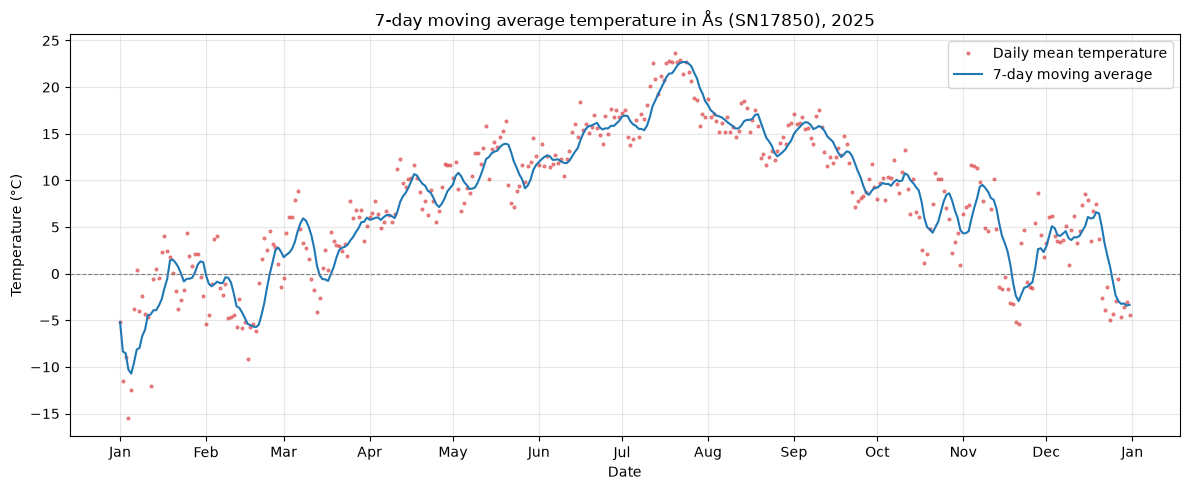

In [16]:
# Apply the function to the 2025 mean temperature from task 1
df['moving_avg'] = moving_average(df['value'], window=7)

# Plot daily temperature as points and the moving average as a line
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['referenceTime'], df['value'], '.', color='tab:red',
        markersize=4, alpha=0.5, label='Daily mean temperature')
ax.plot(df['referenceTime'], df['moving_avg'], color='tab:blue',
        linewidth=1.5, label='7-day moving average')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('7-day moving average temperature in Ås (SN17850), 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

The moving average smooths out the daily variation and makes the seasonal trend easier to see.

# References

[1] Norwegian Meteorological Institute. *Frost – Python example*. https://frost.met.no/python_example.html (accessed 13 October 2026)

[2] Norwegian Meteorological Institute. *Frost API*. https://frost.met.no (accessed 13 October 2026). Weather data from station SN17850, Ås.

[3] Norwegian Meteorological Institute *Article about heatwaves* https://www.met.no/vaer-og-klima/ekstremvaervarsler-og-andre-farevarsler/vaerfenomener-som-kan-gi-farevarsel-fra-met/hetebolger (accessed 14 october)
